<a href="https://colab.research.google.com/github/Anitha-Naresh/Liquid-Waste-Management_Sample_Data/blob/main/MAIN_PROJECT_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Liquid Waste Management Data Analysis
Python Data Analytics Final Project
Project objective: Perform end-to-end exploratory data analysis (EDA) on the Liquid Waste Management dataset, including data loading, data cleaning, descriptive statistics, visualizations, and evidence-based insights.

## Dataset: Liquid Waste Management_Sample_Data(1).csv

## Tools: Python, Pandas, NumPy, Matplotlib, Seaborn
## Project workflow
1. Load the dataset and inspect its structure.
2. Clean missing values, duplicates, and data types.
3. Perform univariate, bivariate, and multivariate analysis.
4. Use groupby, a pivot table, and correlation analysis.
5. Create at least 10 visualizations.
6. Summarize at least 5 insights based on the actual results.
Run the notebook from top to bottom. When prompted, upload the supplied CSV file. Do not type or assume results in advance; the analysis and insights are generated from the dataset.

## 1. Import libraries and load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Upload the supplied CSV file from your computer.
uploaded = files.upload()
csv_file = next((name for name in uploaded.keys() if name.lower().endswith(".csv")), None)

if csv_file is None:
    raise ValueError("Please upload the Liquid Waste Management CSV file.")

df_raw = pd.read_csv(csv_file)
df = df_raw.copy()

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Saving Liquid Waste Management_Sample_Data.csv to Liquid Waste Management_Sample_Data.csv
Dataset loaded successfully.
Rows: 500
Columns: 17


,State Name (state_name),State Code (state_code),District Name (district_name),District Code (district_code),Block Name (block_name),Block Code (block_code),Gram Panchayat Name (gp_name),Gram Panchayat Code (gp_code),Village Name (village_name),Village Code (village_code),Is LGD Hierarchy Exact Mapped (is_lgd_exact_mapping),Asset (asset),Sbm (sbm),Mgnrega (mnerga),Mopr (mopr),Shared With Other Village(SBM-G) (shared_other_vil),Households Covered(%) (hhs_covered_per)
0,Himachal Pradesh,2,Kangra,18,Pragpur,162,Sehri,8754,Sehri (199),10726,True,Community Grey Water Management Systems,0,0,0,0.0,0.0
1,Arunachal Pradesh,12,West Kameng,242,Nafra,6804,West Sachung Najangpong,298423,Najangpong,261719,True,Drainage facility available in village,1,0,0,NaN,NaN
2,Jammu And Kashmir,1,Kulgam,622,Qaimoh,9,Tarigam,241706,Tarigam Devsar,3916,True,Drainage facility available in village,2,0,0,NaN,NaN
3,Madhya Pradesh,23,Mandla,415,Bichhiya,3900,Kariagaon,142673,Kariyagaon,493195,True,Drainage facility available in village,1,0,0,NaN,NaN
4,Himachal Pradesh,2,Hamirpur,17,Bijhari,147,Nanawan,8051,Biar Khurd (35/15),17541,True,Community Soak/Leach/Magic Pits,0,0,0,NaN,0.0


## 2. Initial overview

In [ ]:
print("Dataset dimensions:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nNumerical descriptive statistics:")
display(df.describe())

print("\\nDescriptive statistics for all columns:")
display(df.describe(include="all").T)

print("\\nMissing values by column:")
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)
display(missing_summary)

Dataset dimensions: (500, 17)
\nColumn names:
['State Name (state_name)', 'State Code (state_code)', 'District Name (district_name)', 'District Code (district_code)', 'Block Name (block_name)', 'Block Code (block_code)', 'Gram Panchayat Name (gp_name)', 'Gram Panchayat Code (gp_code)', 'Village Name (village_name)', 'Village Code (village_code)', 'Is LGD Hierarchy Exact Mapped (is_lgd_exact_mapping)', 'Asset (asset)', 'Sbm (sbm)', 'Mgnrega (mnerga)', 'Mopr (mopr)', 'Shared With Other Village(SBM-G) (shared_other_vil)', 'Households Covered(%) (hhs_covered_per)']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   State Name (state_name)                               500 non-null    object 
 1   State Code (state_code)                

,State Code (state_code),District Code (district_code),Block Code (block_code),Gram Panchayat Code (gp_code),Village Code (village_code),Sbm (sbm),Mgnrega (mnerga),Mopr (mopr),Shared With Other Village(SBM-G) (shared_other_vil),Households Covered(%) (hhs_covered_per)
count,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,160.0,313.000000
mean,16.52800,308.542000,2902.768000,124603.042000,317958.580000,2.726000,0.096000,0.054000,0.0,36.813291
std,8.76738,194.400337,1902.548496,75060.656478,197068.853311,14.886711,0.890151,0.404241,0.0,43.755158
min,1.00000,2.000000,9.000000,0.000000,492.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,9.00000,140.000000,1167.000000,67746.500000,142571.000000,0.000000,0.000000,0.000000,0.0,0.000000
50%,19.00000,310.500000,2980.000000,112612.500000,312726.000000,1.000000,0.000000,0.000000,0.0,5.750000
75%,23.00000,435.750000,4008.250000,175550.500000,475819.250000,2.000000,0.000000,0.000000,0.0,97.650000
max,36.00000,770.000000,7449.000000,298895.000000,925884.000000,320.000000,15.000000,6.000000,0.0,100.000000


\nDescriptive statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State Name (state_name),500,26,Uttar Pradesh,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State Code (state_code),500.0,NaN,NaN,NaN,16.528,8.76738,1.0,9.0,19.0,23.0,36.0
District Name (district_name),500,313,Azamgarh,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District Code (district_code),500.0,NaN,NaN,NaN,308.542,194.400337,2.0,140.0,310.5,435.75,770.0
Block Name (block_name),500,470,Gubbi,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Block Code (block_code),500.0,NaN,NaN,NaN,2902.768,1902.548496,9.0,1167.0,2980.0,4008.25,7449.0
Gram Panchayat Name (gp_name),500,499,Gopalpur,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gram Panchayat Code (gp_code),500.0,NaN,NaN,NaN,124603.042,75060.656478,0.0,67746.5,112612.5,175550.5,298895.0
Village Name (village_name),500,496,Kurubarahalli,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Village Code (village_code),500.0,NaN,NaN,NaN,317958.58,197068.853311,492.0,142571.0,312726.0,475819.25,925884.0


\nMissing values by column:


,Missing_Count,Missing_Percentage
Shared With Other Village(SBM-G) (shared_other_vil),340,68.0
Households Covered(%) (hhs_covered_per),187,37.4
State Name (state_name),0,0.0
State Code (state_code),0,0.0
District Name (district_name),0,0.0
Block Code (block_code),0,0.0
Gram Panchayat Name (gp_name),0,0.0
District Code (district_code),0,0.0
Block Name (block_name),0,0.0
Village Name (village_name),0,0.0


## 3. Data cleaning and preprocessing

The initial inspection found no duplicate rows. The Shared With Other Village(SBM-G) field has a high proportion of missing values, so it will be excluded from the cleaned analysis dataset. The household coverage field is retained because it is analytically useful. Its original values are preserved in Households_Covered_Original; a separate analysis field is median-imputed and accompanied by a flag so imputed values can be identified. Charts that describe actual household coverage use only observed values, not imputed values.

In [ ]:
# Standardize column names to make them easier to use in Python.
df.columns = [
    col.strip().lower().replace("%", "percent").replace("-", "_").replace(" ", "_")
    for col in df.columns
]

print("Column names after standardization:")
print(df.columns.tolist())

# Remove exact duplicate rows (if any).
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()
print("Duplicate rows removed:", duplicates_before)

# Identify the standardized names corresponding to the two fields.
shared_col = next((c for c in df.columns if "shared_with_other_village" in c), None)
coverage_col = next((c for c in df.columns if "households_covered" in c), None)

# Remove the column with high missingness, based on the initial data inspection.
if shared_col is not None:
    print(f"Removing {shared_col!r}: {df[shared_col].isna().sum()} missing values out of {len(df)}.")
    df = df.drop(columns=[shared_col])

# Preserve observed household coverage and record which values are missing.
if coverage_col is not None:
    df["households_covered_original"] = df[coverage_col]
    df["households_covered_was_missing"] = df[coverage_col].isna()
    median_coverage = df[coverage_col].median()
    df["households_covered_imputed"] = df[coverage_col].fillna(median_coverage)
    print("Median used only in the separate imputed analysis field:", median_coverage)

# Convert text fields to trimmed strings; preserve missing values.
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()

# Correct likely numeric fields safely. Any non-convertible entries become missing.
for col in df.columns:
    if any(term in col for term in ["_code", "sbm", "mnerga", "mopr", "percent", "covered"]):
        if df[col].dtype == "object":
            df[col] = pd.to_numeric(df[col], errors="coerce")

print("\\nCleaned dataset dimensions:", df.shape)
print("\\nMissing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing_Count").head(15))
display(df.head())

Column names after standardization:
['state_name_(state_name)', 'state_code_(state_code)', 'district_name_(district_name)', 'district_code_(district_code)', 'block_name_(block_name)', 'block_code_(block_code)', 'gram_panchayat_name_(gp_name)', 'gram_panchayat_code_(gp_code)', 'village_name_(village_name)', 'village_code_(village_code)', 'is_lgd_hierarchy_exact_mapped_(is_lgd_exact_mapping)', 'asset_(asset)', 'sbm_(sbm)', 'mgnrega_(mnerga)', 'mopr_(mopr)', 'shared_with_other_village(sbm_g)_(shared_other_vil)', 'households_covered(percent)_(hhs_covered_per)']
Duplicate rows removed: 0
Removing 'shared_with_other_village(sbm_g)_(shared_other_vil)': 340 missing values out of 500.
Median used only in the separate imputed analysis field: 5.75
\nCleaned dataset dimensions: (500, 19)
\nMissing values after cleaning:


,Missing_Count
households_covered(percent)_(hhs_covered_per),187
households_covered_original,187
state_name_(state_name),0
district_name_(district_name),0
state_code_(state_code),0
district_code_(district_code),0
block_name_(block_name),0
gram_panchayat_code_(gp_code),0
village_name_(village_name),0
block_code_(block_code),0


,state_name_(state_name),state_code_(state_code),district_name_(district_name),district_code_(district_code),block_name_(block_name),block_code_(block_code),gram_panchayat_name_(gp_name),gram_panchayat_code_(gp_code),village_name_(village_name),village_code_(village_code),is_lgd_hierarchy_exact_mapped_(is_lgd_exact_mapping),asset_(asset),sbm_(sbm),mgnrega_(mnerga),mopr_(mopr),households_covered(percent)_(hhs_covered_per),households_covered_original,households_covered_was_missing,households_covered_imputed
0,Himachal Pradesh,2,Kangra,18,Pragpur,162,Sehri,8754,Sehri (199),10726,True,Community Grey Water Management Systems,0,0,0,0.0,0.0,False,0.00
1,Arunachal Pradesh,12,West Kameng,242,Nafra,6804,West Sachung Najangpong,298423,Najangpong,261719,True,Drainage facility available in village,1,0,0,NaN,NaN,True,5.75
2,Jammu And Kashmir,1,Kulgam,622,Qaimoh,9,Tarigam,241706,Tarigam Devsar,3916,True,Drainage facility available in village,2,0,0,NaN,NaN,True,5.75
3,Madhya Pradesh,23,Mandla,415,Bichhiya,3900,Kariagaon,142673,Kariyagaon,493195,True,Drainage facility available in village,1,0,0,NaN,NaN,True,5.75
4,Himachal Pradesh,2,Hamirpur,17,Bijhari,147,Nanawan,8051,Biar Khurd (35/15),17541,True,Community Soak/Leach/Magic Pits,0,0,0,0.0,0.0,False,0.00


## 4. Prepare analysis columns

In [ ]:
# Find important columns by their standardized names.
state_col = next((c for c in df.columns if c.startswith("state_name")), None)
district_col = next((c for c in df.columns if c.startswith("district_name")), None)
village_col = next((c for c in df.columns if c.startswith("village_name")), None)
asset_col = next((c for c in df.columns if c.startswith("asset_") or c == "asset"), None)

# The scheme fields in the supplied file are Sbm (sbm), Mgnrega (mnerga), and Mopr (mopr).
sbm_col = next((c for c in df.columns if c == "sbm_(sbm)" or c.endswith("_sbm") or c == "sbm"), None)
mgnrega_col = next((c for c in df.columns if "mnerga" in c or "mgnrega" in c), None)
mopr_col = next((c for c in df.columns if c == "mopr_(mopr)" or c.endswith("_mopr") or c == "mopr"), None)

# Print detected fields so the notebook is transparent and easy to troubleshoot.
print("State:", state_col)
print("District:", district_col)
print("Village:", village_col)
print("Asset:", asset_col)
print("SBM:", sbm_col)
print("MGNREGA:", mgnrega_col)
print("MOPR:", mopr_col)
print("Coverage:", coverage_col)

# Numeric columns used for general statistical analysis.
numeric_cols = [c for c in df.select_dtypes(include=np.number).columns.tolist() if c not in ["households_covered_original", "households_covered_imputed"]]
print("\\nNumeric columns:", numeric_cols)

State: state_name_(state_name)
District: district_name_(district_name)
Village: village_name_(village_name)
Asset: asset_(asset)
SBM: sbm_(sbm)
MGNREGA: mgnrega_(mnerga)
MOPR: mopr_(mopr)
Coverage: households_covered(percent)_(hhs_covered_per)
\nNumeric columns: ['state_code_(state_code)', 'district_code_(district_code)', 'block_code_(block_code)', 'gram_panchayat_code_(gp_code)', 'village_code_(village_code)', 'sbm_(sbm)', 'mgnrega_(mnerga)', 'mopr_(mopr)', 'households_covered(percent)_(hhs_covered_per)']


## 5. Univariate analysis

In [ ]:
# Frequency table for asset categories.
if asset_col:
    print("Asset category counts:")
    display(df[asset_col].value_counts(dropna=False).to_frame("Record_Count"))

# Frequency table for states.
if state_col:
    print("Records by state (top 15):")
    display(df[state_col].value_counts().head(15).to_frame("Record_Count"))

# Numeric summary.
display(df[numeric_cols].describe().T if numeric_cols else pd.DataFrame())

Asset category counts:


,Record_Count
asset_(asset),
Drainage facility available in village,187
Community Grey Water Management Systems,160
Community Soak/Leach/Magic Pits,153


Records by state (top 15):


,Record_Count
state_name_(state_name),
Uttar Pradesh,84
Madhya Pradesh,41
Odisha,40
Rajasthan,40
Maharashtra,30
Bihar,30
West Bengal,29
Jharkhand,28
Karnataka,26


,count,mean,std,min,25%,50%,75%,max
state_code_(state_code),500.0,16.528000,8.767380,1.0,9.0,19.00,23.00,36.0
district_code_(district_code),500.0,308.542000,194.400337,2.0,140.0,310.50,435.75,770.0
block_code_(block_code),500.0,2902.768000,1902.548496,9.0,1167.0,2980.00,4008.25,7449.0
gram_panchayat_code_(gp_code),500.0,124603.042000,75060.656478,0.0,67746.5,112612.50,175550.50,298895.0
village_code_(village_code),500.0,317958.580000,197068.853311,492.0,142571.0,312726.00,475819.25,925884.0
sbm_(sbm),500.0,2.726000,14.886711,0.0,0.0,1.00,2.00,320.0
mgnrega_(mnerga),500.0,0.096000,0.890151,0.0,0.0,0.00,0.00,15.0
mopr_(mopr),500.0,0.054000,0.404241,0.0,0.0,0.00,0.00,6.0
households_covered(percent)_(hhs_covered_per),313.0,36.813291,43.755158,0.0,0.0,5.75,97.65,100.0


## 6. Groupby analysis and pivot table

In [ ]:
if asset_col and state_col:
    asset_by_state = pd.crosstab(df[state_col], df[asset_col])
    print("Pivot table: record counts by state and asset type")
    display(asset_by_state.head(20))
else:
    asset_by_state = pd.DataFrame()
    print("State or asset column was not detected; pivot table skipped.")

if state_col:
    state_summary = df.groupby(state_col).agg(
        Record_Count=(state_col, "size")
    ).sort_values("Record_Count", ascending=False)
    print("Records per state:")
    display(state_summary.head(20))

if asset_col:
    asset_summary = df.groupby(asset_col).size().sort_values(ascending=False).to_frame("Record_Count")
    print("Records by asset type:")
    display(asset_summary)

Pivot table: record counts by state and asset type


asset_(asset),Community Grey Water Management Systems,Community Soak/Leach/Magic Pits,Drainage facility available in village
state_name_(state_name),,,
Andhra Pradesh,5,4,7
Arunachal Pradesh,0,1,3
Assam,6,5,8
Bihar,9,9,12
Chhattisgarh,1,4,7
Gujarat,4,3,5
Haryana,7,2,2
Himachal Pradesh,9,5,1
Jammu And Kashmir,0,3,2


Records per state:


,Record_Count
state_name_(state_name),
Uttar Pradesh,84
Madhya Pradesh,41
Odisha,40
Rajasthan,40
Bihar,30
Maharashtra,30
West Bengal,29
Jharkhand,28
Karnataka,26


Records by asset type:


,Record_Count
asset_(asset),
Drainage facility available in village,187
Community Grey Water Management Systems,160
Community Soak/Leach/Magic Pits,153


## 7. Bivariate and multivariate analysis

In [ ]:
# Correlation analysis for numeric columns.
# Remove constant columns because they cannot contribute to correlation.
corr_data = df[numeric_cols].copy() if numeric_cols else pd.DataFrame()
if not corr_data.empty:
    corr_data = corr_data.loc[:, corr_data.nunique(dropna=True) > 1]
    if corr_data.shape[1] >= 2:
        corr_matrix = corr_data.corr(numeric_only=True)
        display(corr_matrix)
    else:
        corr_matrix = pd.DataFrame()
        print("At least two non-constant numeric columns are needed for correlation.")
else:
    corr_matrix = pd.DataFrame()
    print("No numeric columns found for correlation analysis.")

# Coverage summary uses observed values only.
coverage_observed = (
    pd.to_numeric(df["households_covered_original"], errors="coerce").dropna()
    if "households_covered_original" in df.columns else pd.Series(dtype=float)
)
if not coverage_observed.empty:
    print("Observed household coverage summary (missing values excluded):")
    display(coverage_observed.describe().to_frame("Households_Covered_Percent"))

,state_code_(state_code),district_code_(district_code),block_code_(block_code),gram_panchayat_code_(gp_code),village_code_(village_code),sbm_(sbm),mgnrega_(mnerga),mopr_(mopr),households_covered(percent)_(hhs_covered_per)
state_code_(state_code),1.000000,0.865427,0.783632,0.633527,0.929499,-0.040285,0.086191,-0.022762,-0.039020
district_code_(district_code),0.865427,1.000000,0.693496,0.622143,0.811613,-0.036212,0.094233,-0.031179,-0.053645
block_code_(block_code),0.783632,0.693496,1.000000,0.620600,0.748955,-0.049642,0.083122,-0.037417,-0.099184
gram_panchayat_code_(gp_code),0.633527,0.622143,0.620600,1.000000,0.584008,-0.036400,0.071756,-0.013388,-0.060104
village_code_(village_code),0.929499,0.811613,0.748955,0.584008,1.000000,-0.043849,0.056445,-0.019382,-0.074057
sbm_(sbm),-0.040285,-0.036212,-0.049642,-0.036400,-0.043849,1.000000,0.007887,0.556263,0.178173
mgnrega_(mnerga),0.086191,0.094233,0.083122,0.071756,0.056445,0.007887,1.000000,-0.014435,-0.008205
mopr_(mopr),-0.022762,-0.031179,-0.037417,-0.013388,-0.019382,0.556263,-0.014435,1.000000,0.070403
households_covered(percent)_(hhs_covered_per),-0.039020,-0.053645,-0.099184,-0.060104,-0.074057,0.178173,-0.008205,0.070403,1.000000


Observed household coverage summary (missing values excluded):


,Households_Covered_Percent
count,313.000000
mean,36.813291
std,43.755158
min,0.000000
25%,0.000000
50%,5.750000
75%,97.650000
max,100.000000


## 8. Visualizations (10 required plots)

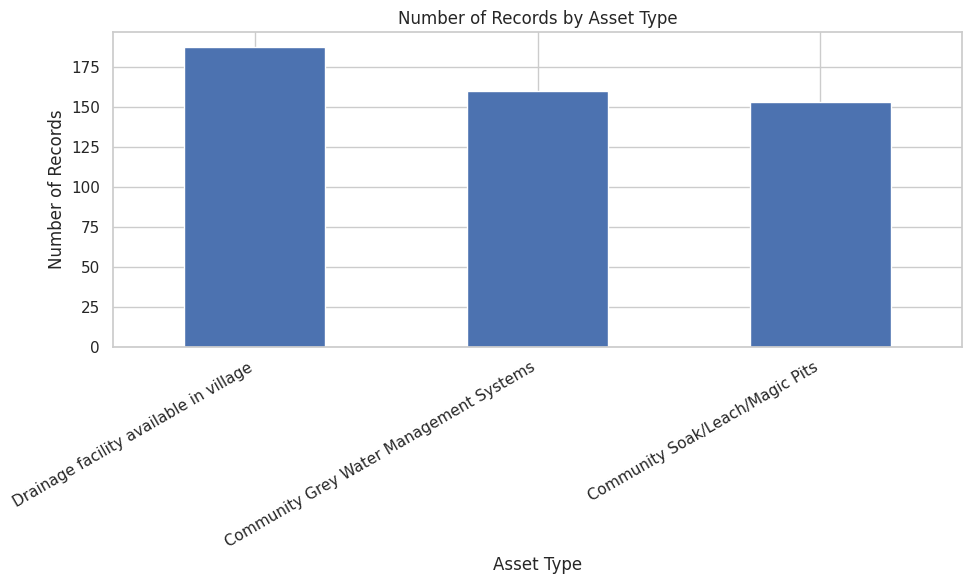

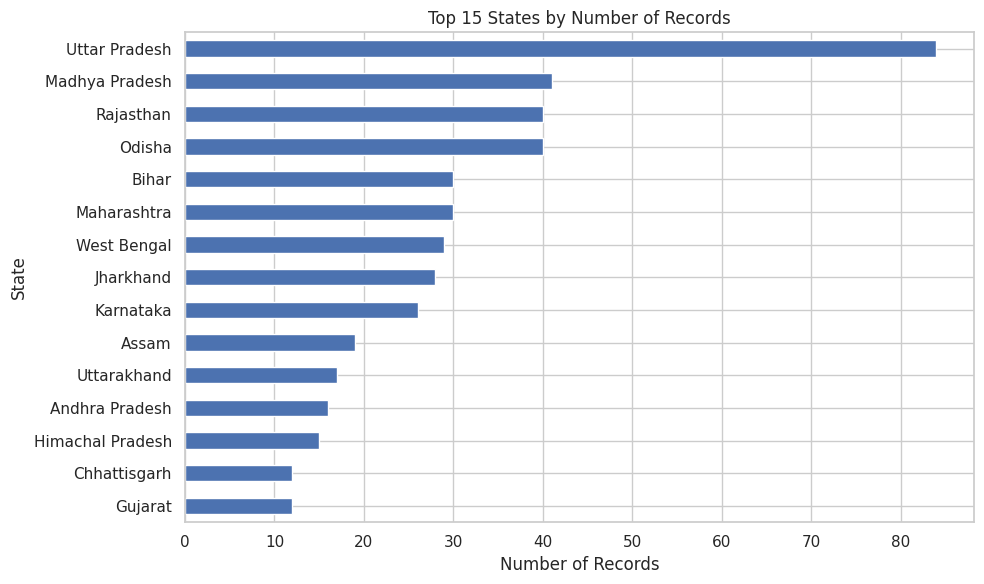

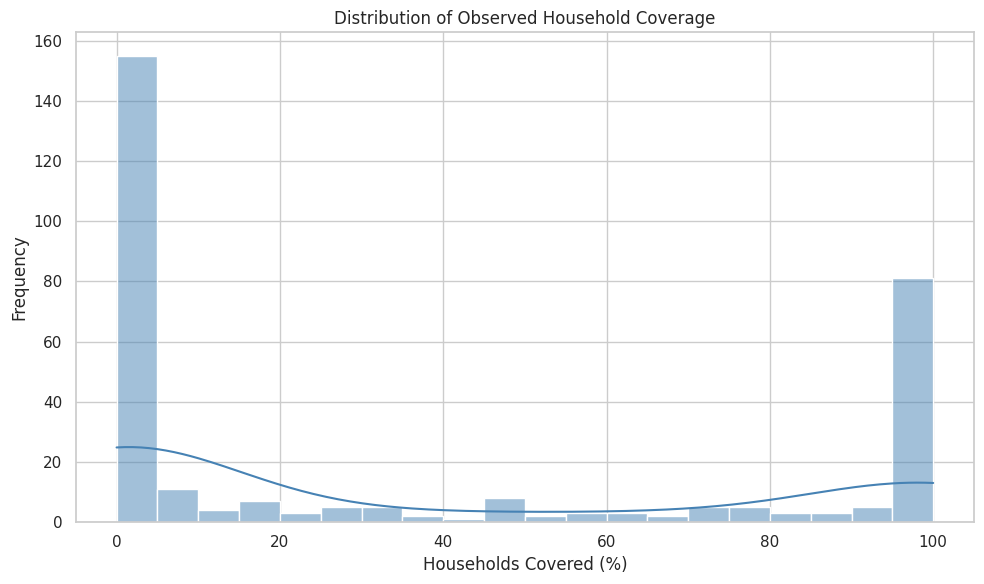

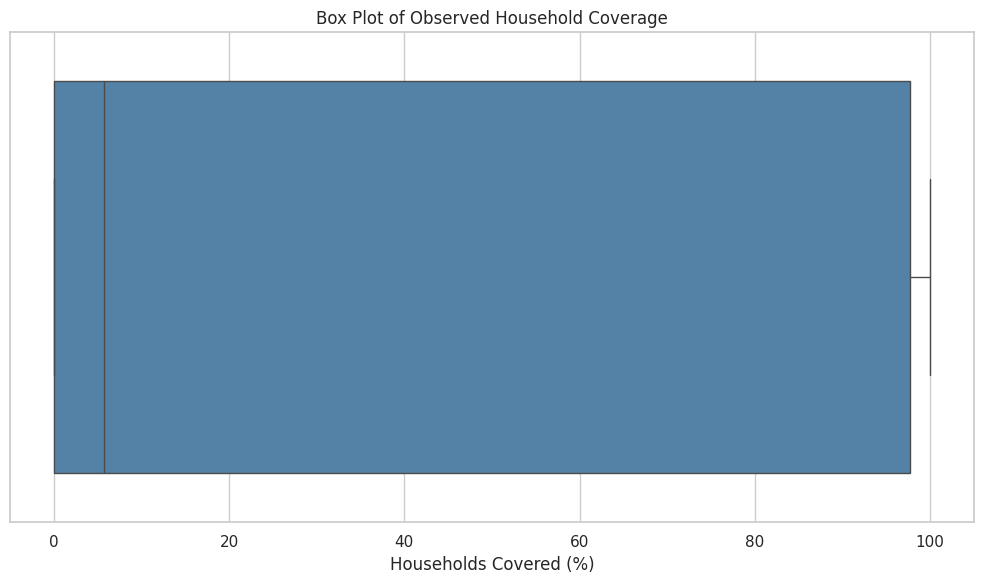

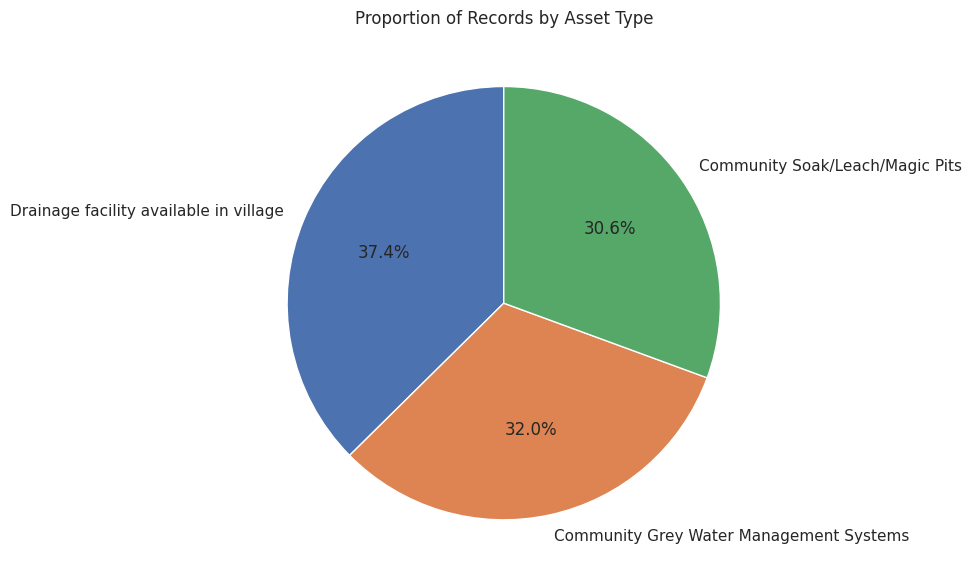

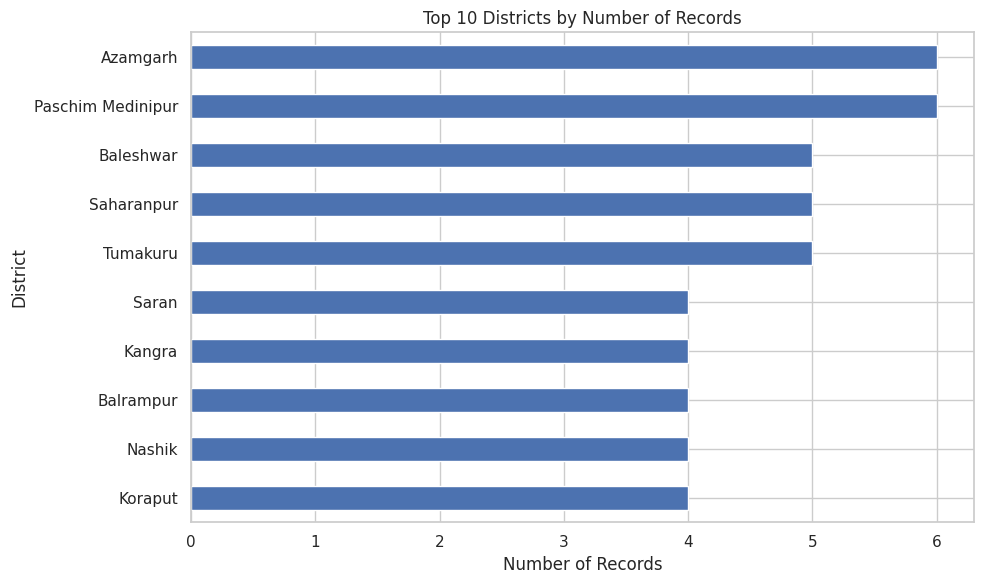

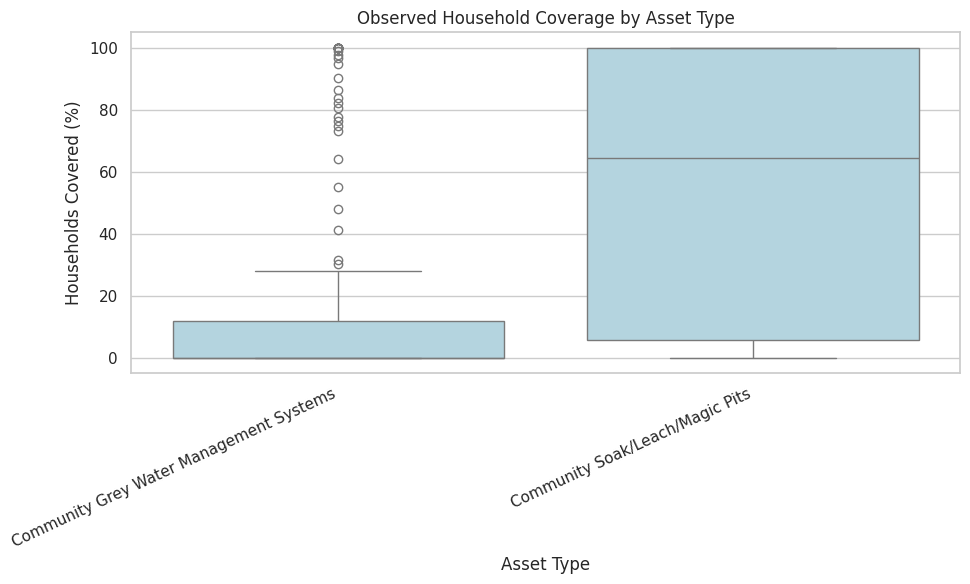

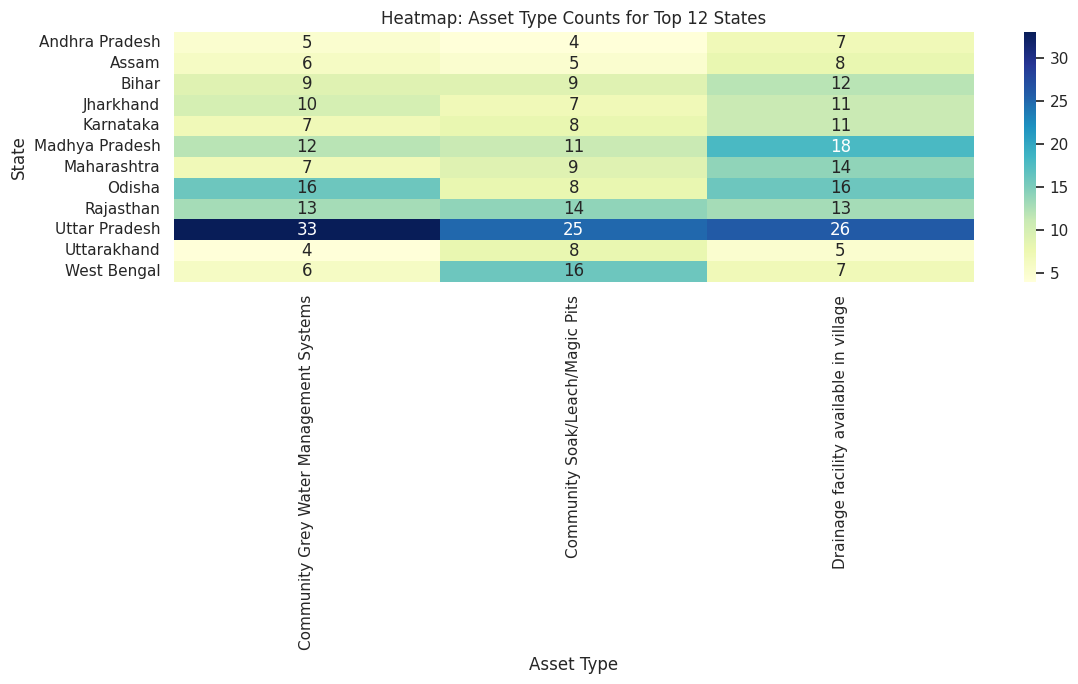

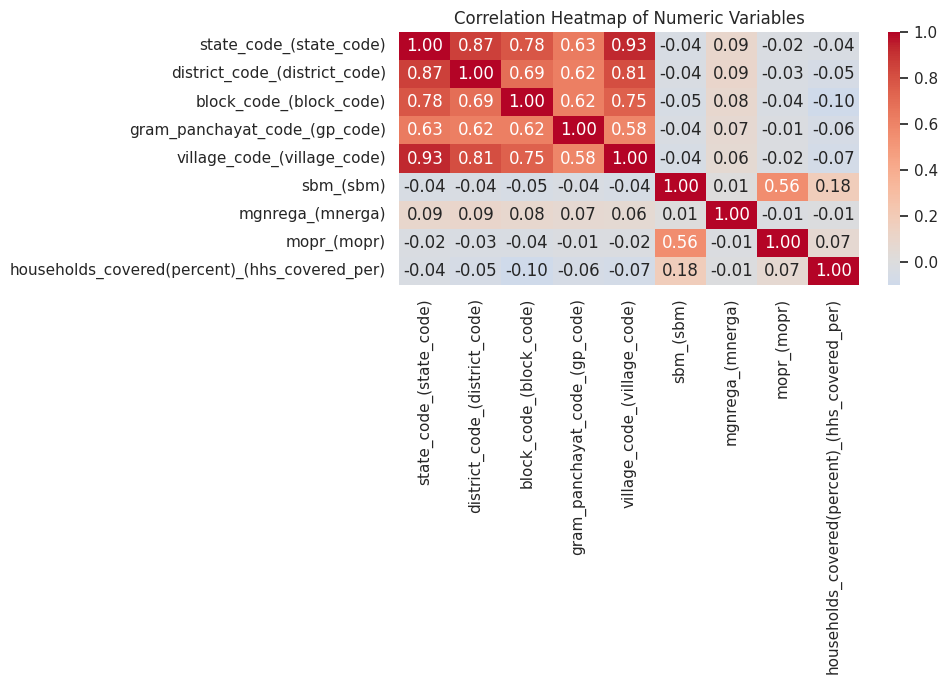

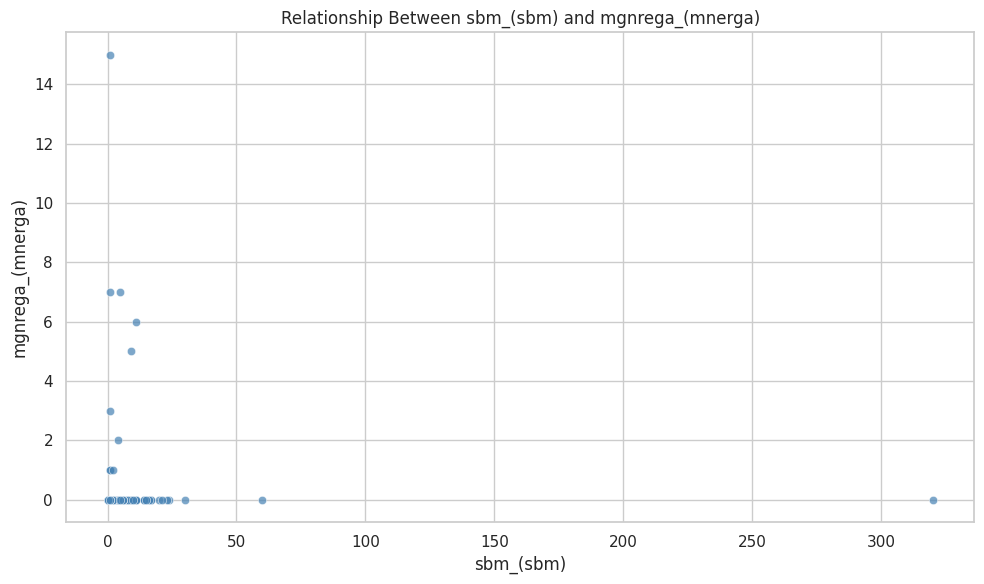

In [ ]:
# Plot 1: Asset category bar chart
if asset_col:
    ax = df[asset_col].value_counts().plot(kind="bar", title="Number of Records by Asset Type")
    ax.set_xlabel("Asset Type")
    ax.set_ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 1 skipped: asset column not detected.")

# Plot 2: State-wise record counts (top 15)
if state_col:
    ax = df[state_col].value_counts().head(15).sort_values().plot(kind="barh", title="Top 15 States by Number of Records")
    ax.set_xlabel("Number of Records")
    ax.set_ylabel("State")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 2 skipped: state column not detected.")

# Plot 3: Histogram of observed household coverage
if not coverage_observed.empty:
    plt.figure()
    sns.histplot(coverage_observed, bins=20, kde=True, color="steelblue")
    plt.title("Distribution of Observed Household Coverage")
    plt.xlabel("Households Covered (%)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 3 skipped: no observed household coverage values.")

# Plot 4: Box plot of observed household coverage
if not coverage_observed.empty:
    plt.figure()
    sns.boxplot(x=coverage_observed, color="steelblue")
    plt.title("Box Plot of Observed Household Coverage")
    plt.xlabel("Households Covered (%)")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 4 skipped: no observed household coverage values.")

# Plot 5: Pie chart of asset categories
if asset_col:
    counts = df[asset_col].value_counts()
    plt.figure()
    plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
    plt.title("Proportion of Records by Asset Type")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 5 skipped: asset column not detected.")

# Plot 6: Top 10 districts by record count
if district_col:
    district_counts = df[district_col].value_counts().head(10).sort_values()
    plt.figure()
    district_counts.plot(kind="barh")
    plt.title("Top 10 Districts by Number of Records")
    plt.xlabel("Number of Records")
    plt.ylabel("District")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 6 skipped: district column not detected.")

# Plot 7: Household coverage by asset type (observed coverage only)
if asset_col and "households_covered_original" in df.columns:
    plot_df = df[[asset_col, "households_covered_original"]].copy()
    plot_df["households_covered_original"] = pd.to_numeric(plot_df["households_covered_original"], errors="coerce")
    plot_df = plot_df.dropna()
    if not plot_df.empty:
        plt.figure()
        sns.boxplot(data=plot_df, x=asset_col, y="households_covered_original", color="lightblue")
        plt.title("Observed Household Coverage by Asset Type")
        plt.xlabel("Asset Type")
        plt.ylabel("Households Covered (%)")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("Plot 7 skipped: no rows have both asset type and observed coverage.")
else:
    print("Plot 7 skipped: required columns not detected.")

# Plot 8: Heatmap of asset type by state (top 12 states)
if asset_col and state_col:
    top_states = df[state_col].value_counts().head(12).index
    heat_data = pd.crosstab(df.loc[df[state_col].isin(top_states), state_col], df.loc[df[state_col].isin(top_states), asset_col])
    if not heat_data.empty:
        plt.figure(figsize=(12, 7))
        sns.heatmap(heat_data, annot=True, fmt="d", cmap="YlGnBu")
        plt.title("Heatmap: Asset Type Counts for Top 12 States")
        plt.xlabel("Asset Type")
        plt.ylabel("State")
        plt.tight_layout()
        plt.show()
else:
    print("Plot 8 skipped: state or asset column not detected.")

# Plot 9: Correlation heatmap
if not corr_matrix.empty:
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap of Numeric Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 9 skipped: insufficient numeric variation for correlation.")

# Plot 10: Scatter plot of two numeric columns with the greatest variation, excluding codes where possible
candidate_cols = [c for c in numeric_cols if not c.endswith("_code") and "code" not in c and df[c].nunique(dropna=True) > 1]
if len(candidate_cols) >= 2:
    # Prefer scheme counts and coverage if present; otherwise use the first two suitable numeric columns.
    preferred = [c for c in [sbm_col, mgnrega_col, mopr_col, "households_covered_original"] if c and c in candidate_cols]
    x_col = preferred[0] if len(preferred) >= 1 else candidate_cols[0]
    y_col = next((c for c in preferred if c != x_col), next((c for c in candidate_cols if c != x_col), None))
    if y_col:
        scatter_df = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
        if not scatter_df.empty:
            plt.figure()
            sns.scatterplot(data=scatter_df, x=x_col, y=y_col, alpha=0.7, color="steelblue")
            plt.title(f"Relationship Between {x_col} and {y_col}")
            plt.xlabel(x_col)
            plt.ylabel(y_col)
            plt.tight_layout()
            plt.show()
        else:
            print("Plot 10 skipped: no valid numeric pairs.")
    else:
        print("Plot 10 skipped: no second numeric column found.")
else:
    print("Plot 10 skipped: fewer than two suitable numeric columns.")

## 9. Generate at least 5 data-based insights

In [ ]:
insights = []

insights.append(f"The dataset contains {len(df):,} records after duplicate removal and preprocessing.")

if asset_col:
    asset_counts = df[asset_col].value_counts()
    if not asset_counts.empty:
        insights.append(
            f"The most frequently recorded asset type is '{asset_counts.index[0]}' "
            f"with {int(asset_counts.iloc[0])} records ({asset_counts.iloc[0] / len(df) * 100:.1f}% of records)."
        )

if state_col:
    state_counts = df[state_col].value_counts()
    if not state_counts.empty:
        insights.append(
            f"The state with the highest number of records is '{state_counts.index[0]}' "
            f"with {int(state_counts.iloc[0])} records. This is a record count, not necessarily a measure of performance."
        )

if district_col:
    district_counts = df[district_col].value_counts()
    if not district_counts.empty:
        insights.append(
            f"The district with the highest number of records is '{district_counts.index[0]}' "
            f"with {int(district_counts.iloc[0])} records."
        )

if not coverage_observed.empty:
    insights.append(
        f"Observed household coverage has a mean of {coverage_observed.mean():.2f}% "
        f"and a median of {coverage_observed.median():.2f}%, calculated after excluding missing coverage values."
    )
    insights.append(
        f"There are {int(df['households_covered_original'].isna().sum())} records with missing household coverage "
        f"out of {len(df)} records ({df['households_covered_original'].isna().mean() * 100:.1f}%)."
    )

if asset_col:
    asset_counts = df[asset_col].value_counts()
    if len(asset_counts) > 1:
        insights.append(
            f"The difference between the most and least frequent asset categories is "
            f"{int(asset_counts.max() - asset_counts.min())} records."
        )

if not corr_matrix.empty:
    pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack()
    if not pairs.empty:
        strongest_pair = pairs.abs().idxmax()
        value = pairs.loc[strongest_pair]
        insights.append(
            f"The strongest absolute pairwise correlation among the numeric variables analysed is between "
            f"'{strongest_pair[0]}' and '{strongest_pair[1]}' (correlation = {value:.2f}). "
            "Correlation does not establish causation."
        )

print("KEY INSIGHTS")
for i, insight in enumerate(insights[:8], start=1):
    print(f"{i}. {insight}")

if len(insights) < 5:
    print("\\nFewer than five insights could be generated automatically. Review the tables and plots above and add further observations supported by the displayed results.")

KEY INSIGHTS
1. The dataset contains 500 records after duplicate removal and preprocessing.
2. The most frequently recorded asset type is 'Drainage facility available in village' with 187 records (37.4% of records).
3. The state with the highest number of records is 'Uttar Pradesh' with 84 records. This is a record count, not necessarily a measure of performance.
4. The district with the highest number of records is 'Azamgarh' with 6 records.
5. Observed household coverage has a mean of 36.81% and a median of 5.75%, calculated after excluding missing coverage values.
6. There are 187 records with missing household coverage out of 500 records (37.4%).
7. The difference between the most and least frequent asset categories is 34 records.
8. The strongest absolute pairwise correlation among the numeric variables analysed is between 'state_code_(state_code)' and 'village_code_(village_code)' (correlation = 0.93). Correlation does not establish causation.


## 10. Final conclusion

In [ ]:
print("CONCLUSION")
print("- The analysis examined the distribution of liquid-waste-management asset records across locations and asset types.")
print("- Household coverage statistics were calculated from observed values, excluding missing observations.")
print("- Missingness and data-cleaning decisions were documented rather than hidden.")
print("- Use the tables, charts, and generated insights above to write a short conclusion in your own words.")
print("\\nRECOMMENDATIONS")
print("1. Investigate why household coverage values are missing before making operational decisions.")
print("2. Verify the dataset source and definitions for the scheme-related columns before interpreting them as outcomes.")
print("3. Use additional time-series or household-level data if you want to measure changes over time or estimate actual service performance.")

# Export the cleaned analysis dataset for reference.
cleaned_file = "liquid_waste_management_cleaned.csv"
df.to_csv(cleaned_file, index=False)
print(f"\\nCleaned dataset saved as: {cleaned_file}")

CONCLUSION
- The analysis examined the distribution of liquid-waste-management asset records across locations and asset types.
- Household coverage statistics were calculated from observed values, excluding missing observations.
- Missingness and data-cleaning decisions were documented rather than hidden.
- Use the tables, charts, and generated insights above to write a short conclusion in your own words.
\nRECOMMENDATIONS
1. Investigate why household coverage values are missing before making operational decisions.
2. Verify the dataset source and definitions for the scheme-related columns before interpreting them as outcomes.
3. Use additional time-series or household-level data if you want to measure changes over time or estimate actual service performance.
\nCleaned dataset saved as: liquid_waste_management_cleaned.csv
